In [145]:
'''Primeramente, vamos a instalar las dependencias necesarias para realizar
las consultas dentro de la base de datos LOTUS'''
%pip install pandas
%pip install rdkit py3Dmol


In [ ]:
'''Luego, se importan las bibliotecas Requests, Pandas, RDKit y sus módulos Chem y Draw'''
import pandas as pd
from rdkit import Chem
from rdkit.Chem import Draw

Luego, podemos hacer una búsqueda sencilla empleando el nombre de un producto natural como por ejemplo, el mentol, presente en productos cosméticos como labiales, esencias y el famoso Vaporrub.

> [!WARNING] 
> Los nombres de los compuestos deben estar exclusivamente en inglés

Status code del query: 200
Estructura química del query "solanapyrone"


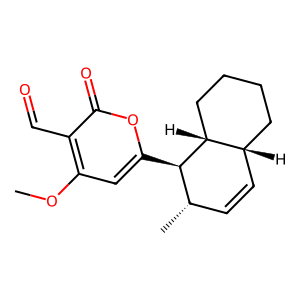

In [155]:
'''Búsqueda por nombre:

Nos van a solicitar el nombre de un producto natural, para posteriormente ejecutar un query simple a la API REST de LOTUS.
Este bloque nos va a devolver el status del query y la estrucutra química del compuesto que estamos buscando'''

compound=input("Introduce el nombre de un producto natural (en inglés):")
url=f"https://lotus.naturalproducts.net/api/search/simple?query={compound}"
response=requests.get(url)
print(f"Status code del query: {response.status_code}")
data=response.json()
data
df=pd.json_normalize(data,record_path=['naturalProducts'],meta=['originalQuery','determinedInputType'])
querySmiles=df[['id','traditional_name','smiles']].iloc[0,2]
mol=Chem.MolFromSmiles(querySmiles)
img=Draw.MolToImage(mol,size=(300,300))
print(f"Estructura química del query \"{compound}\"")
img


O, podemos emplear una búsqueda por SMILES de la estructura de la molécula
Por ejemplo, podemos buscar:
- Menthol, el compuesto responsable del aroma a menta de *Menta piperita* (menta): C[C@@H]1CC[C@H]([C@@H](C1)O)C(C)C
- Cocaine, un alcaloide de la planta de coca (*Erythroxylum coca*): COC(=O)[C@H]1[C@@H](OC(=O)c2ccccc2)C[C@@H]2CC[C@H]1N2C
- Geraniol, presente en las flores de geranio (*Geranium* sp.): CC(=CCC/C(=C/CO)/C)C
- Delphinidin, una antociandinina que da colores azules a flores como las dalias y las petunias: C1=C(C=C(C(=C1O)[O-])O)C2=C(C=C3C(=CC(=O)C=C3O2)O)O 

Status code del query: 200
Estructura química del query "CC1=C(C(=O)C=C2C1=CC=C3[C@]2(CC[C@@]4([C@@]3(CC[C@@]5([C@H]4C[C@](CC5)(C)C(=O)O)C)C)C)C)O "


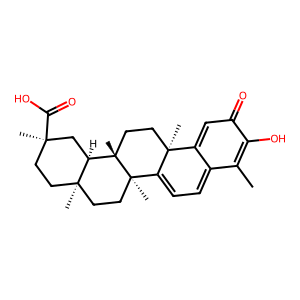

In [136]:
smiles=input("Introduce el SMILES de una molécula aquí")
url=f"https://lotus.naturalproducts.net/api/search/substructure?type=vf&max-hits=10&smiles={smiles}"
response=requests.get(url)
print(f"Status code del query: {response.status_code}")
data=response.json()
mol=Chem.MolFromSmiles(smiles)
img=Draw.MolToImage(mol,size=(300,300))
print(f"Estructura química del query \"{smiles}\"")
img



In [148]:
# Plot en 3D de la molécula query en SMILES (opcional)
from rdkit.Chem import AllChem, rdCoordGen
from rdkit.Chem.Draw import IPythonConsole 
IPythonConsole.ipython_useSVG=True
import py3Dmol

'''Armado, inserción de átomos de hidrógeno y optimización con MMFF94
La función recibe un objeto mol de RDKit, para posteriormente generar
coordenadas XYZ para cada átomo que constituye la molécula'''

def mol3d(mol):
    mol=Chem.MolFromSmiles(smiles)
    rdCoordGen.AddCoords(mol)
    mol=Chem.AddHs(mol,addCoords=True)
    AllChem.EmbedMolecule(mol)
    AllChem.MMFFOptimizeMolecule(mol)
    return mol
def smiles2mol3d(mol):
    rdCoordGen.AddCoords(mol)
    mol=Chem.AddHs(mol,addCoords=True)
    AllChem.EmbedMolecule(mol)
    AllChem.MMFFOptimizeMolecule(mol)

mol=mol3d(mol=smiles)

view = py3Dmol.view(
    data=Chem.MolToMolBlock(mol),  # Convert the RDKit molecule for py3Dmol
    style={"stick": {}, "sphere": {"scale": 0.3}}
)
view.zoomTo()

3Dmol.js failed to load for some reason. Please check your browser console for error messages.

In [156]:
# Organizando los datos en un dataframe de Pandas
df=pd.json_normalize(data['naturalProducts'])
df=df.dropna(axis=1,how='any')
df.drop(list(df.filter(regex="fragment*")),axis=1,inplace=True)
# Vamos a imprimir varias características de nuestra tabla
print("¿Cuántas filas y columnas tiene el archivo?","\n",df.shape[0],"columnas y", df.shape[1],"filas\n")
print("Esta es la descripción de la tabla:\n")
df=df.filter(['id','lotus_id','traditional_name','molecular_weight','contains_sugar','smiles'])
display(df)

¿Cuántas filas y columnas tiene el archivo? 
 6 columnas y 87 filas

Esta es la descripción de la tabla:



,id,lotus_id,traditional_name,molecular_weight,contains_sugar,smiles
0,604b8aa012e499616275d522,LTS0071736,solanapyrone a,302.365562,0,COc1cc([C@@H]2[C@@H](C)C=C[C@H]3CCCC[C@H]32)oc...
1,604b84eb12e499616274f202,LTS0151140,solanapyrone d,302.365562,0,COc1cc([C@@H]2[C@H](C)C=C[C@@H]3CCCC[C@H]32)oc...
2,604b830312e499616274a5bf,LTS0157896,solanapyrone e,304.381444,0,COc1cc([C@@H]2[C@H](C)C=C[C@@H]3CCCC[C@H]32)oc...
3,604b827c12e49961627490a3,LTS0215681,solanapyrone c,347.406229,0,C[C@H]1C=C[C@H]2CCCC[C@H]2[C@@H]1c1cc(ONCCO)c(...
4,604b770912e499616272aaf4,LTS0002179,solanapyrone c,331.406824,0,C[C@H]1C=C[C@H]2CCCC[C@H]2[C@@H]1c1cc(NCCO)c(C...
5,604b72da12e4996162721d52,LTS0114907,solanapyrone b,304.381444,0,COc1cc([C@@H]2[C@@H](C)C=C[C@H]3CCCC[C@H]32)oc...


Estructuras moleculares similares a nuestro query COc1cc([C@@H]2[C@@H](C)C=C[C@H]3CCCC[C@H]32)oc(=O)c1C=O
0    solanapyrone a
1    solanapyrone d
2    solanapyrone e
3    solanapyrone c
4    solanapyrone c
5    solanapyrone b
Name: traditional_name, dtype: object


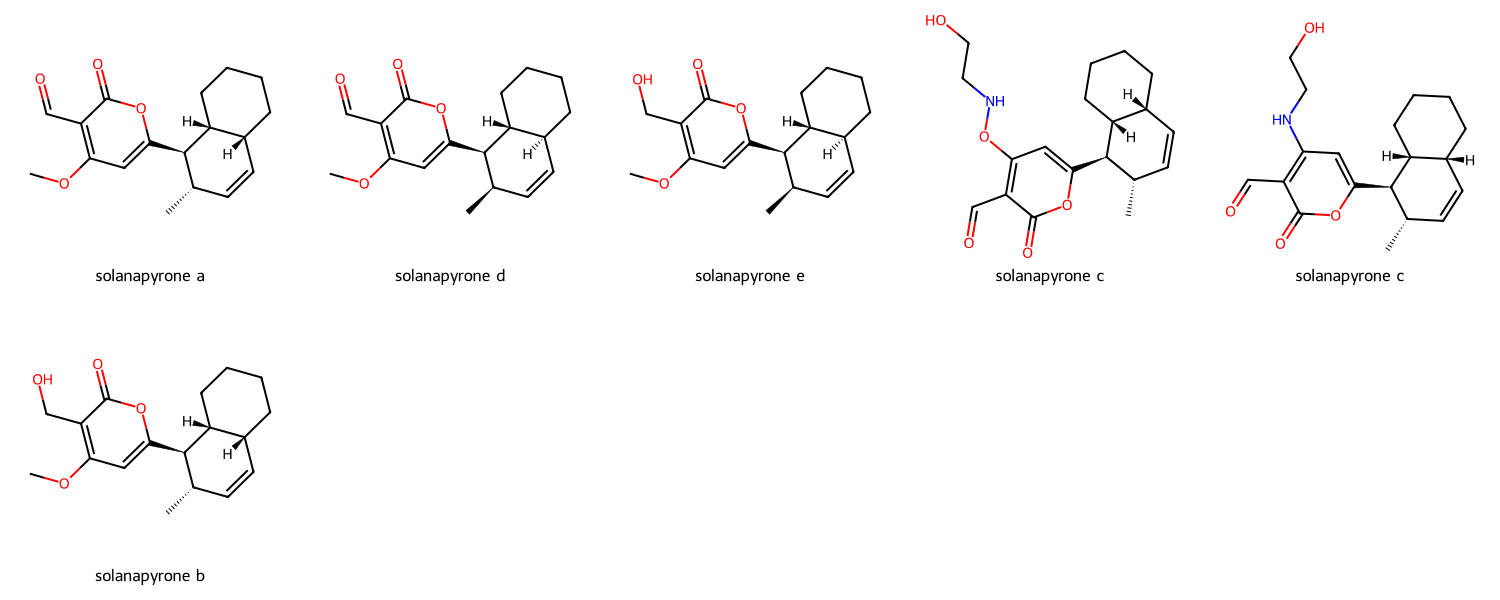

In [157]:
# Imágenes de estructuras similares al query:
mol =  [ Chem.MolFromSmiles(x) for x in df['smiles']]
names=list(df['traditional_name'])
img=Draw.MolsToGridImage(mol,molsPerRow=5,legends=names,subImgSize=(300,300))  
print(f"Estructuras moleculares similares a nuestro query {querySmiles}")
print(df['traditional_name'])
img